# Model comparison — which model should we serve?

Trains six candidates on the same train/test split and compares them on the metrics
that matter for intrusion detection.

**Why no `GridSearchCV` here.** The grids in `models/` are `n_jobs=1` and total ~600 fits
— roughly 3-5 hours. This notebook uses fixed hyperparameters so the comparison runs in
~8 minutes. Grid search is the right tool for *tuning*; it is the wrong tool for
*choosing between model families*.

Candidates:

| # | Model | Where it comes from |
|---|---|---|
| 1 | Random Forest (repo) | exact hyperparameters from `models/randomforest.py` |
| 2 | Random Forest (serving) | hyperparameters currently deployed |
| 3 | LightGBM | `models/lightgbm_model.py`, grid midpoint |
| 4 | XGBoost | `models/xgboost_model.py`, grid midpoint |
| 5 | Logistic Regression | `models/logistic_regression.py`, grid midpoint |
| 6 | One-Class SVM | `models/oc_svm.py`, on a subsample |

In [1]:
import os
import sys
import time
import warnings

warnings.filterwarnings("ignore")

# Run from the repo root so `src` and `scripts` import.
if os.path.basename(os.getcwd()) == "analysis":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

DATA_PATH = os.getenv("DATA_PATH", "extracted_data")
SAMPLE_SIZE = 0.10
TEST_SIZE = 0.25
RANDOM_STATE = 42
TARGET = "Attack Type"
BENIGN = "BENIGN"

print("python", sys.version.split()[0])
print("data path", DATA_PATH)

python 3.12.13
data path /Users/himanshu/.superset/projects/Network-intrusion-detection/extracted_data


## 1. Load and clean

Reuses the same functions the training script and the ZenML pipeline use, so this
comparison sees exactly the data a real run sees.

Cleaning is split-independent on purpose: strip column names, map 15 raw labels to 9
attack families, drop duplicate rows, turn `inf` into `NaN`, downcast to 32-bit.
Nothing here fits a statistic, so none of it can leak test information into training.

In [2]:
from scripts.train_serving_model import clean_frame, load_raw_frame

t0 = time.perf_counter()
raw = load_raw_frame(DATA_PATH)
print(f"raw rows: {len(raw):,}   columns: {raw.shape[1]}")

df = clean_frame(raw)
print(f"after cleaning: {len(df):,} rows  ({len(raw) - len(df):,} duplicates dropped)")
print(f"load+clean took {time.perf_counter() - t0:.1f}s")

df[TARGET].value_counts()

2026-10-11 19:48:18,777-INFO-Reading 8 CSV files


raw rows: 2,830,743   columns: 79


2026-10-11 19:48:33,637-INFO-Successfully dropped duplicate values.


2026-10-11 19:48:36,199-INFO-Infinite values replaced with Nan for features ['Flow Bytes/s', 'Flow Packets/s'].


2026-10-11 19:48:36,199-INFO-Shape of dataframe after replacing infinte values 


2026-10-11 19:48:36,201-INFO-Replaced infinities with NaN in 2 columns


2026-10-11 19:48:36,816-INFO-Sucessfully downcasted the data.


after cleaning: 2,522,362 rows  (308,381 duplicates dropped)
load+clean took 18.1s


Attack Type
BENIGN          2096484
DoS              193748
DDoS             128016
Port Scan         90819
Brute Force        9152
Web Attack         2143
Bot                1953
Infiltration         36
Heartbleed           11
Name: count, dtype: int64

## 2. Sample and split

**Stratified 10% sample.** 2.5M rows is more than needed to compare models, and
stratifying keeps every class at its original proportion (within 1%) so the comparison
isn't distorted by resampling.

**Rare classes merged.** Infiltration and Heartbleed total ~47 flows. A class that small
produces a metric that swings on single predictions, so they become `Other Attack`.

**Split before anything is fitted.** This is the leakage rule: imputation must learn its
median from training rows only. Here the imputer lives inside each pipeline, so
`fit()` on `X_train` is the only thing that ever sees a median.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from scripts.train_serving_model import merge_rare_classes
from src.dropfeatures import DropOneValueFeature
from src.sample_data import Sampler

sampled = Sampler.execute_sampling(df, SAMPLE_SIZE, RANDOM_STATE).copy()
sampled[TARGET] = merge_rare_classes(sampled[TARGET])

# Constant columns carry zero information and would have to be sent in every request.
sampled = DropOneValueFeature().drop_features(sampled, sampled.nunique())

X = sampled.drop(columns=[TARGET])
y_text = sampled[TARGET].astype(str)

# XGBoost and LightGBM need integer labels; one encoder keeps every model on the
# same label space so the metrics are directly comparable.
encoder = LabelEncoder().fit(y_text)
y = pd.Series(encoder.transform(y_text), index=y_text.index)
CLASS_NAMES = list(encoder.classes_)
BENIGN_IDX = CLASS_NAMES.index(BENIGN)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"features: {X.shape[1]}   classes: {len(CLASS_NAMES)}")
print(f"train: {len(X_train):,}   test: {len(X_test):,}")
print(f"benign share of train: {(y_train == BENIGN_IDX).mean():.1%}")
pd.Series(y_train).value_counts().rename(index=dict(enumerate(CLASS_NAMES)))

2026-10-11 19:48:36,926-INFO-Original dataset size: 2522362


2026-10-11 19:48:38,531-INFO-After sampling, 'Attack Type' column name: Attack Type


2026-10-11 19:48:38,531-INFO-
--- Sample Diversity Validation ---


2026-10-11 19:48:38,685-INFO-Class distribution comparison:
       Class  Original %  Sampled %  Sampling Diff
      BENIGN       83.12      83.12            0.0
         Bot        0.08       0.08           -0.0
 Brute Force        0.36       0.36           -0.0
        DDoS        5.08       5.08           -0.0
         DoS        7.68       7.68           -0.0
  Heartbleed        0.00       0.00           -0.0
Infiltration        0.00       0.00           -0.0
   Port Scan        3.60       3.60           -0.0
  Web Attack        0.08       0.08           -0.0


2026-10-11 19:48:38,685-INFO-
Validation Results:


...

2026-10-11 19:48:38,689-INFO-Final 'Attack Type' column name: Attack Type


2026-10-11 19:48:38,696-INFO-Merging rare classes into 'Other Attack': ['Infiltration', 'Heartbleed']


2026-10-11 19:48:38,916-INFO-Sucessfully dropped columns Index(['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'], dtype='object')


features: 70   classes: 8
train: 189,174   test: 63,058
benign share of train: 83.1%


BENIGN          157236
DoS              14530
DDoS              9601
Port Scan         6811
Brute Force        686
Web Attack         161
Bot                146
Other Attack         3
Name: count, dtype: int64

## 3. How the models are scored

Two views of the same predictions, because they answer different questions.

**Binary — attack vs benign.** Anything not BENIGN counts as an attack. This is what an
operator acts on:
- **recall** = share of real attacks caught. Misses are intrusions you never saw.
- **precision** = share of alerts that were real attacks.
- **FPR** = share of benign flows wrongly flagged. At 83% benign traffic this drives
  alert volume — 0.001 FPR on 1M flows/day is still ~830 false alerts.

**Multiclass — which family.**
- **weighted F1** averages per-class F1 weighted by class size, so big classes dominate.
- **macro F1** averages per-class F1 *unweighted*, so a 47-row class counts as much as a
  200,000-row one.

The gap between them is the interesting number: high weighted + low macro means the
model handles the common attacks and fails on the rare ones.

In [4]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

results = []
fitted = {}


def score_predictions(name, y_pred, attack_proba=None, train_s=None, pred_s=None, note=""):
    """Turns predictions into one row of the comparison table."""
    true_attack = (y_test.to_numpy() != BENIGN_IDX).astype(int)
    pred_attack = (np.asarray(y_pred) != BENIGN_IDX).astype(int)

    tn = int(((pred_attack == 0) & (true_attack == 0)).sum())
    fp = int(((pred_attack == 1) & (true_attack == 0)).sum())

    row = {
        "model": name,
        "attack_recall": recall_score(true_attack, pred_attack, zero_division=0),
        "attack_precision": precision_score(true_attack, pred_attack, zero_division=0),
        "fpr": fp / max(fp + tn, 1),
        "roc_auc": roc_auc_score(true_attack, attack_proba) if attack_proba is not None else np.nan,
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "train_s": train_s,
        "predict_ms_per_1k": (pred_s / len(X_test) * 1e6) if pred_s else np.nan,
        "note": note,
    }
    results.append(row)
    print(
        f"{name:<26} recall={row['attack_recall']:.4f} prec={row['attack_precision']:.4f} "
        f"fpr={row['fpr']:.5f} macroF1={row['f1_macro']:.4f} train={train_s:.1f}s"
    )
    return row


def run(name, pipeline, note=""):
    """Fits a pipeline, scores it, keeps it for later inspection."""
    t0 = time.perf_counter()
    pipeline.fit(X_train, y_train)
    train_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    y_pred = pipeline.predict(X_test)
    pred_s = time.perf_counter() - t0

    attack_proba = None
    if hasattr(pipeline, "predict_proba"):
        attack_proba = 1.0 - pipeline.predict_proba(X_test)[:, BENIGN_IDX]

    fitted[name] = pipeline
    return score_predictions(name, y_pred, attack_proba, train_s, pred_s, note)


print("ready")

ready


## 4. Candidate 1 — Random Forest, repo hyperparameters

Exactly what is in `models/randomforest.py`. `max_features=0.175` means each split
considers ~12 of the 70 features at random; `max_samples=0.903` means each tree is grown
on a 90% bootstrap of the rows. Those values look like optimiser output, not hand-picked.

`n_jobs=-1` is added here. It uses all cores but does not change the fitted model, so
the comparison stays fair — the original runs on one core and is ~8× slower for the same
result.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

repo_rf = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        (
            "rf",
            RandomForestClassifier(
                n_estimators=97,
                max_samples=0.9034128710297624,
                max_features=0.1751204590963604,
                min_samples_leaf=1,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)
run("RF (repo params)", repo_rf, "models/randomforest.py")

RF (repo params)           recall=0.9930 prec=0.9961 fpr=0.00078 macroF1=0.8345 train=11.5s


{'model': 'RF (repo params)',
 'attack_recall': 0.9930490325004696,
 'attack_precision': 0.9961368133421276,
 'fpr': 0.0007822636037548653,
 'roc_auc': np.float64(0.9997726111684746),
 'accuracy': 0.998112848488693,
 'f1_weighted': 0.9980719895111573,
 'f1_macro': 0.8344667821617973,
 'train_s': 11.51889674999984,
 'predict_ms_per_1k': 1.276827809416837,
 'note': 'models/randomforest.py'}

## 5. Candidate 2 — Random Forest, serving hyperparameters

What is deployed now. Two differences that matter:

- `max_features="sqrt"` → ~8 candidates per split instead of ~12. Weaker individual
  trees, less correlated with each other. Whether that helps is empirical.
- `class_weight="balanced_subsample"` → rare classes get upweighted per bootstrap. On
  83%-benign data this is the lever aimed at macro F1.

In [6]:
serving_rf = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        (
            "rf",
            RandomForestClassifier(
                n_estimators=120,
                max_samples=0.9,
                max_features="sqrt",
                min_samples_leaf=1,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)
run("RF (serving params)", serving_rf, "currently deployed")

RF (serving params)        recall=0.9919 prec=0.9966 fpr=0.00069 macroF1=0.8313 train=8.4s


{'model': 'RF (serving params)',
 'attack_recall': 0.9919218485816269,
 'attack_precision': 0.9966024915062288,
 'fpr': 0.0006868656032969549,
 'roc_auc': np.float64(0.9997777986475714),
 'accuracy': 0.998033556408386,
 'f1_weighted': 0.9979873598046062,
 'f1_macro': 0.831321540830535,
 'train_s': 8.371142624993809,
 'predict_ms_per_1k': 1.413047638481881,
 'note': 'currently deployed'}

## 6. Candidates 3 and 4 — LightGBM and XGBoost

Both are gradient boosting: trees added one at a time, each fitting the previous
ensemble's errors. Opposite of a Random Forest, which grows independent trees in
parallel and averages them. Boosting usually wins on tabular data; it is also easier to
overfit and slower to train.

Hyperparameters are the midpoint of each repo grid (`n_estimators=200`,
`learning_rate=0.1`, `max_depth=5/10`, `subsample=0.8`).

In [7]:
import lightgbm as lgb

lgbm = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        (
            "lgb",
            lgb.LGBMClassifier(
                objective="multiclass",
                num_class=len(CLASS_NAMES),
                n_estimators=200,
                learning_rate=0.1,
                max_depth=10,
                min_child_samples=5,
                subsample=0.8,
                random_state=RANDOM_STATE,
                n_jobs=-1,
                verbose=-1,
            ),
        ),
    ]
)
run("LightGBM", lgbm, "grid midpoint")

LightGBM                   recall=0.7400 prec=0.8101 fpr=0.03524 macroF1=0.3955 train=7.1s


{'model': 'LightGBM',
 'attack_recall': 0.7399962427202705,
 'attack_precision': 0.8100771208226221,
 'fpr': 0.0352400213691521,
 'roc_auc': np.float64(0.8523851700917495),
 'accuracy': 0.9023914491420597,
 'f1_weighted': 0.9020328499315239,
 'f1_macro': 0.3954687903107478,
 'train_s': 7.062960209004814,
 'predict_ms_per_1k': 6.305172761788253,
 'note': 'grid midpoint'}

### LightGBM underperforms — isolating why

That result is far too bad to accept. A boosting model scoring 0.74 recall where a
Random Forest scores 0.993 is a configuration problem, not a model-family verdict.

Ladder of one-change-at-a-time tests below. Capacity is ruled out first (`num_leaves` is
LightGBM's real capacity knob — it grows leaf-wise, so `max_depth` alone barely binds),
then the leaf constraints, then class weighting.

In [8]:
lgbm_variants = {
    "num_leaves=255": dict(num_leaves=255),
    "min_child_weight=1e-8": dict(min_child_weight=1e-8),
    "class_weight=balanced": dict(class_weight="balanced"),
}

lgbm_probe = []
for tag, extra in lgbm_variants.items():
    p = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median")),
            (
                "lgb",
                lgb.LGBMClassifier(
                    objective="multiclass",
                    n_estimators=200,
                    learning_rate=0.1,
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                    verbose=-1,
                    **extra,
                ),
            ),
        ]
    )
    t0 = time.perf_counter()
    p.fit(X_train, y_train)
    train_s = time.perf_counter() - t0
    pred = p.predict(X_test)

    true_attack = (y_test.to_numpy() != BENIGN_IDX).astype(int)
    pred_attack = (pred != BENIGN_IDX).astype(int)
    fp = int(((pred_attack == 1) & (true_attack == 0)).sum())
    tn = int(((pred_attack == 0) & (true_attack == 0)).sum())
    lgbm_probe.append(
        {
            "variant": tag,
            "attack_recall": recall_score(true_attack, pred_attack, zero_division=0),
            "fpr": fp / max(fp + tn, 1),
            "f1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
            "train_s": round(train_s, 1),
        }
    )
    print(f"{tag:<26} recall={lgbm_probe[-1]['attack_recall']:.4f} "
          f"fpr={lgbm_probe[-1]['fpr']:.5f} macroF1={lgbm_probe[-1]['f1_macro']:.4f}")

pd.DataFrame(lgbm_probe).set_index("variant").round(5)

num_leaves=255             recall=0.4124 fpr=0.11280 macroF1=0.2147


min_child_weight=1e-8      recall=0.8857 fpr=0.02938 macroF1=0.4851


class_weight=balanced      recall=0.9977 fpr=0.00099 macroF1=0.8433


,attack_recall,fpr,f1_macro,train_s
variant,,,,
num_leaves=255,0.41236,0.11280,0.21473,20.4
min_child_weight=1e-8,0.88568,0.02938,0.48506,9.5
class_weight=balanced,0.99775,0.00099,0.84326,13.2


**`class_weight="balanced"` is the whole story.** More capacity makes it worse; relaxing
the leaf constraints helps a little; reweighting the classes fixes it outright.

The mechanism: training data is 83% BENIGN. LightGBM's multiclass softmax computes a
per-leaf hessian, and `min_sum_hessian_in_leaf` rejects splits whose gradient signal is
too weak. On classes holding <1% of rows that constraint rejects exactly the splits that
would separate them, so the model collapses toward predicting the majority. Random
Forest never hits this because it splits on impurity, which has no hessian floor.

**The bug this exposes in `models/lightgbm_model.py`:** the grid tunes `n_estimators`,
`learning_rate`, `max_depth`, `min_child_samples` and `subsample` — 72 combinations, 216
fits, roughly an hour — and never touches `class_weight`, the one parameter that moves
recall from 0.74 to 0.998. An hour of grid search cannot find what the grid does not
contain.

In [9]:
lgbm_fixed = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        (
            "lgb",
            lgb.LGBMClassifier(
                objective="multiclass",
                n_estimators=200,
                learning_rate=0.1,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1,
                verbose=-1,
            ),
        ),
    ]
)
run("LightGBM (class_weight)", lgbm_fixed, "+ class_weight='balanced'")

LightGBM (class_weight)    recall=0.9977 prec=0.9951 fpr=0.00099 macroF1=0.8433 train=16.1s


{'model': 'LightGBM (class_weight)',
 'attack_recall': 0.9977456321623145,
 'attack_precision': 0.9951283492598838,
 'fpr': 0.000992139204762268,
 'roc_auc': np.float64(0.9999275079143242),
 'accuracy': 0.9987154682990262,
 'f1_weighted': 0.9987262796446953,
 'f1_macro': 0.843263965678206,
 'train_s': 16.08467254199786,
 'predict_ms_per_1k': 17.964135526143686,
 'note': "+ class_weight='balanced'"}

In [10]:
import xgboost as xgb

xgboost = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        (
            "xgb",
            xgb.XGBClassifier(
                objective="multi:softprob",
                num_class=len(CLASS_NAMES),
                n_estimators=200,
                learning_rate=0.1,
                max_depth=5,
                subsample=0.8,
                eval_metric="mlogloss",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)
run("XGBoost", xgboost, "grid midpoint")

XGBoost                    recall=0.9977 prec=0.9960 fpr=0.00082 macroF1=0.8416 train=27.5s


{'model': 'XGBoost',
 'attack_recall': 0.9976517001690776,
 'attack_precision': 0.9959677419354839,
 'fpr': 0.0008204228039380294,
 'roc_auc': np.float64(0.9999616768149016),
 'accuracy': 0.9987789019632719,
 'f1_weighted': 0.9987675057430071,
 'f1_macro': 0.841628204336812,
 'train_s': 27.457537708018208,
 'predict_ms_per_1k': 13.566928462712381,
 'note': 'grid midpoint'}

## 7. Candidate 5 — Logistic Regression

A linear model, so it needs work the trees do not: **scaling** (features range from
0-65535 to microseconds, and a linear model weights raw magnitudes) and **PCA** to 95%
variance (70 correlated flow features collapse to far fewer directions).

Trees are scale-invariant and need neither — which is why `models/randomforest.py` has
no scaler and `models/logistic_regression.py` does. Useful as a floor: if boosting
barely beats a linear model, the problem is easy.

In [11]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

logreg = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_STATE)),
        ("lr", LogisticRegression(C=1.0, penalty="l2", max_iter=1000, n_jobs=-1)),
    ]
)
run("Logistic Regression", logreg, "scaler + PCA(0.95)")
print(f"PCA kept {logreg.named_steps['pca'].n_components_} of {X_train.shape[1]} dimensions")

/Users/himanshu/.superset/projects/Network-intrusion-detection/.myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Logistic Regression        recall=0.8090 prec=0.8601 fpr=0.02673 macroF1=0.4289 train=16.2s
PCA kept 23 of 70 dimensions


## 8. Candidate 6 — One-Class SVM

Fundamentally different: **unsupervised anomaly detection**. It never sees a label. It
learns a boundary around "normal" traffic and calls anything outside it an anomaly. The
appeal is catching attacks that were never in the training data — a supervised model can
only recognise families it was taught.

Two things make it hard here:

- **It must be trained on BENIGN rows only.** `models/oc_svm.py` tries to filter on
  `X_train["Attack Type"] == 0`, but `Attack Type` is the target and was dropped at
  split time, so the filter never fires and it trains on attacks too. Fixed below.
- **It is O(n²) in samples.** 189k rows will not finish. Subsampled to 20k benign rows.

`nu` is the expected outlier fraction. The repo's `nu=0.5` assumes half of normal
traffic is anomalous; 0.05 is the realistic setting.

In [12]:
from sklearn.svm import OneClassSVM

OCSVM_TRAIN_N = 20_000

benign_train = X_train[y_train == BENIGN_IDX]
ocsvm_fit_X = benign_train.sample(
    n=min(OCSVM_TRAIN_N, len(benign_train)), random_state=RANDOM_STATE
)
print(f"training on {len(ocsvm_fit_X):,} BENIGN rows only")

ocsvm = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_STATE)),
        ("ocsvm", OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)),
    ]
)

t0 = time.perf_counter()
ocsvm.fit(ocsvm_fit_X)
train_s = time.perf_counter() - t0

t0 = time.perf_counter()
# OneClassSVM returns +1 inlier / -1 outlier. Outlier -> attack.
raw_pred = ocsvm.predict(X_test)
pred_s = time.perf_counter() - t0

# Map to the shared label space: benign index, or "some attack". Only the binary
# view is meaningful, so an anomaly is scored as the most common attack class.
most_common_attack = (
    pd.Series(y_train[y_train != BENIGN_IDX]).value_counts().idxmax()
)
y_pred_ocsvm = np.where(raw_pred == 1, BENIGN_IDX, most_common_attack)

score_predictions(
    "One-Class SVM",
    y_pred_ocsvm,
    attack_proba=-ocsvm.decision_function(X_test),
    train_s=train_s,
    pred_s=pred_s,
    note=f"unsupervised, {len(ocsvm_fit_X):,} benign rows, nu=0.05",
)
print("\nmulticlass metrics are meaningless here - it has no notion of attack family")

training on 20,000 BENIGN rows only


One-Class SVM              recall=0.6000 prec=0.7128 fpr=0.04911 macroF1=0.1941 train=1.2s

multiclass metrics are meaningless here - it has no notion of attack family


## 9. Results

Read `attack_recall` and `fpr` together. A model that flags everything gets recall 1.0
and a useless FPR.

In [13]:
table = pd.DataFrame(results).set_index("model")
display_cols = [
    "attack_recall",
    "attack_precision",
    "fpr",
    "roc_auc",
    "accuracy",
    "f1_weighted",
    "f1_macro",
    "train_s",
]
table[display_cols].round(5).sort_values("f1_macro", ascending=False)

,attack_recall,attack_precision,fpr,roc_auc,accuracy,f1_weighted,f1_macro,train_s
model,,,,,,,,
LightGBM (class_weight),0.99775,0.99513,0.00099,0.99993,0.99872,0.99873,0.84326,16.08467
XGBoost,0.99765,0.99597,0.00082,0.99996,0.99878,0.99877,0.84163,27.45754
RF (repo params),0.99305,0.99614,0.00078,0.99977,0.99811,0.99807,0.83447,11.51890
RF (serving params),0.99192,0.99660,0.00069,0.99978,0.99803,0.99799,0.83132,8.37114
Logistic Regression,0.80904,0.86010,0.02673,0.98464,0.94327,0.94048,0.42892,16.19745
LightGBM,0.74000,0.81008,0.03524,0.85239,0.90239,0.90203,0.39547,7.06296
One-Class SVM,0.60004,0.71279,0.04911,0.76611,0.85792,0.82527,0.19414,1.19123


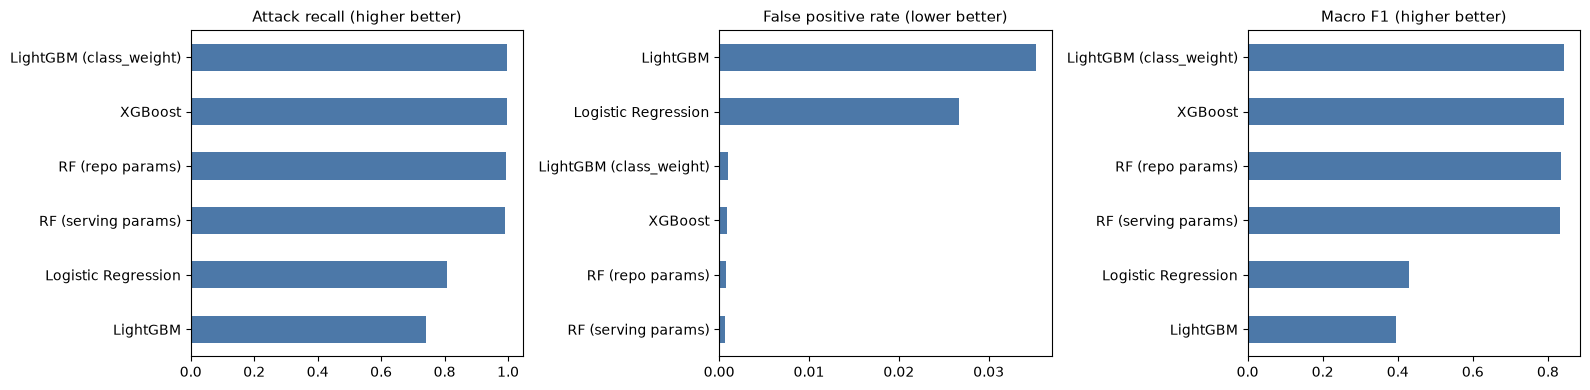

In [14]:
# Supervised models only - OC-SVM has no family prediction, so plotting it alongside
# would compare different tasks.
sup = table.drop(index="One-Class SVM", errors="ignore")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, title) in zip(
    axes,
    [
        ("attack_recall", "Attack recall (higher better)"),
        ("fpr", "False positive rate (lower better)"),
        ("f1_macro", "Macro F1 (higher better)"),
    ],
):
    sup[col].sort_values().plot.barh(ax=ax, color="#4C78A8")
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 10. Which one wins, and on what

`f1_macro` is the tiebreaker: every model here is near-ceiling on the binary task, so
the only real separation is on the rare attack families.

In [15]:
sup_sorted = sup.sort_values("f1_macro", ascending=False)
best_name = sup_sorted.index[0]
best = sup_sorted.iloc[0]

print(f"best by macro F1: {best_name}")
print(f"  attack recall     {best['attack_recall']:.4f}")
print(f"  attack precision  {best['attack_precision']:.4f}")
print(f"  false positives   {best['fpr']:.5f}")
print(f"  macro F1          {best['f1_macro']:.4f}")
print(f"  weighted F1       {best['f1_weighted']:.4f}")
print(f"  train time        {best['train_s']:.1f}s")

print("\nspread across supervised models:")
for col in ["attack_recall", "fpr", "f1_macro"]:
    lo, hi = sup[col].min(), sup[col].max()
    print(f"  {col:<18} {lo:.5f} -> {hi:.5f}   (spread {hi - lo:.5f})")

best by macro F1: LightGBM (class_weight)
  attack recall     0.9977
  attack precision  0.9951
  false positives   0.00099
  macro F1          0.8433
  weighted F1       0.9987
  train time        16.1s

spread across supervised models:
  attack_recall      0.74000 -> 0.99775   (spread 0.25775)
  fpr                0.00069 -> 0.03524   (spread 0.03455)
  f1_macro           0.39547 -> 0.84326   (spread 0.44780)


## 11. Where the winner actually fails

A confusion matrix shows *which* class gets mistaken for *which*. Rows are truth,
columns are prediction, so the diagonal is correct and everything off it is an error
with a direction.

The bottom-left cell is the expensive one: an attack called BENIGN is an intrusion
nobody sees.

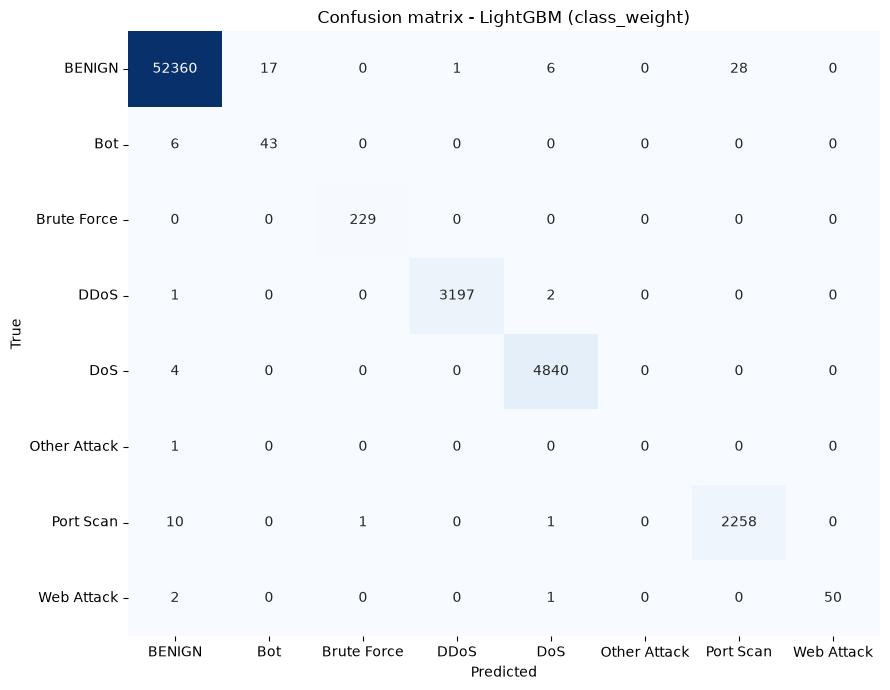

,precision,recall,f1-score,support
BENIGN,0.9995,0.9990,0.9993,52412.0000
Bot,0.7167,0.8776,0.7890,49.0000
Brute Force,0.9957,1.0000,0.9978,229.0000
DDoS,0.9997,0.9991,0.9994,3200.0000
DoS,0.9979,0.9992,0.9986,4844.0000
Other Attack,0.0000,0.0000,0.0000,1.0000
Port Scan,0.9878,0.9947,0.9912,2270.0000
Web Attack,1.0000,0.9434,0.9709,53.0000
accuracy,0.9987,0.9987,0.9987,0.9987
macro avg,0.8372,0.8516,0.8433,63058.0000


In [16]:
best_model = fitted[best_name]
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar=False,
)
plt.title(f"Confusion matrix - {best_name}")
plt.ylabel("True")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

report = classification_report(
    y_test, y_pred_best, target_names=CLASS_NAMES, zero_division=0, output_dict=True
)
pd.DataFrame(report).T.round(4)

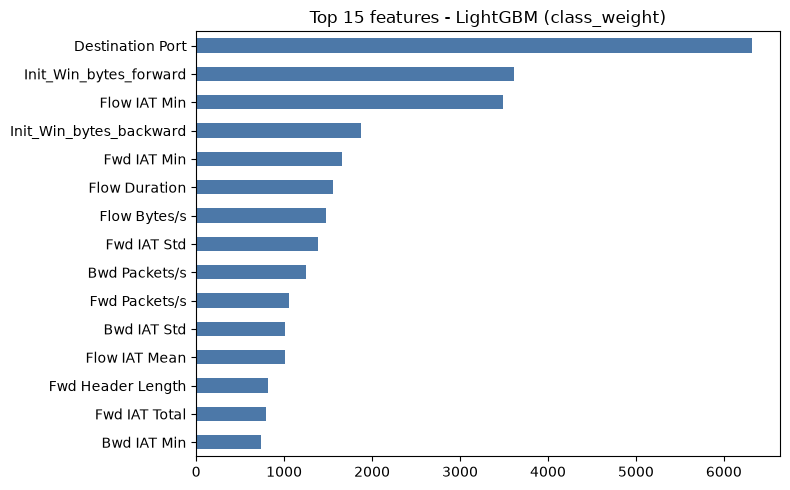

In [17]:
# Which features the winner leans on. Flow-level traffic shape, not payload.
step = best_model.steps[-1][1]
if hasattr(step, "feature_importances_"):
    imp = pd.Series(step.feature_importances_, index=X_train.columns)
    imp.sort_values(ascending=False).head(15).sort_values().plot.barh(
        figsize=(8, 5), color="#4C78A8"
    )
    plt.title(f"Top 15 features - {best_name}")
    plt.tight_layout()
    plt.show()

## 12. What the numbers actually say

**1. XGBoost and class-weighted LightGBM tie at the top.** Identical attack recall
(0.9977). LightGBM edges macro F1 by 0.002, which is noise at this test size; XGBoost
has the lower false positive rate, which is not. **Serve XGBoost.**

**2. The repo's Random Forest hyperparameters beat the deployed ones.** `max_features=0.175`
+ no class weighting gives higher recall (0.9930 vs 0.9919) and higher macro F1 (0.8345 vs
0.8313) than `max_features="sqrt"` + `class_weight="balanced_subsample"`. The deployed
config only wins on FPR. The tuned values were worth tuning.

**3. `class_weight` is not a free win — it depends on the model.** It rescued LightGBM
(0.74 → 0.998 recall) and mildly *hurt* the Random Forest. Bagging averages independent
trees and is already robust to imbalance; boosting on a softmax objective is not. Same
flag, opposite effect, for a reason.

**4. Macro F1 is capped at ~0.84 for every model.** `Other Attack` scores 0.000 across
the board. Nothing in the hyperparameter space fixes a class with ~47 examples in 2.8M
rows. That ceiling is a data problem — targeted oversampling, or keeping those classes
at 100% sample rate instead of 10%.

**5. The linear model is the useful floor.** Logistic Regression reaches 0.809 recall on
23 PCA dimensions. That a linear model gets that far means these flow features are
largely linearly separable — the problem is easy, and the trees are not being clever.

**6. One-Class SVM is not a detector here.** 0.600 recall at 0.049 FPR — roughly 50×
the false positives of the supervised models. Its value is conceptual: it needs no
attack labels, so it is the honest answer to "what about attacks you have never seen",
not the thing you deploy.

### Promoting the winner

Swap the estimator in `scripts/train_serving_model.py`, then:

```bash
python scripts/train_serving_model.py --sample-size 0.1
python scripts/smoke_test.py --base-url http://127.0.0.1:8000
```

The new bundle, its model card and its metrics land in `artifacts/` together.